# Stage 1 (Part 2) – Exploratory Data Analysis

Describes churn using all 7,032 cleaned customers (original service levels kept). Three questions:
- **Q2. Who churns?** – which features are associated with churn
- **Q3. When do customers churn?** – churn by tenure and contract
- **Q4. Is every lost customer equally costly?** – where lost revenue is concentrated

Nothing here is used to fit a model.

## Setup
The data is prepared with the same functions as Stage 1 (`src/features.py`), so the EDA and the models always see identical cleaning rules.

In [1]:
# Cell 1 - Setup: paths, data and chart style
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import features as F

df_raw = pd.read_csv(C.RAW_CSV)
eda = F.add_n_services(F.clean_raw(df_raw))     # original service levels (business-readable)
eda_merged = F.merge_redundant_levels(eda)      # merged levels (used once, as a robustness check)
OVERALL = eda[C.TARGET].mean()

# One chart style for every figure in the thesis
STAYED, CHURNED, BAR, GREY = "#2a78d6", "#eb6834", "#2a78d6", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
C.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
C.TABLES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png")
    print("Saved figure:", name)

print(f"Customers: {len(eda):,}   Churned: {eda[C.TARGET].sum():,}   Churn rate: {OVERALL:.2%}")

Customers: 7,032   Churned: 1,869   Churn rate: 26.58%


## Q2. Who churns?
Categorical features: chi-square test with **Cramér's V** (about 0.1 weak, 0.3 moderate, 0.5 strong). Numeric features: **Mann–Whitney U** with rank-biserial r. P-values are corrected with the **Holm** procedure (20 tests).

In [2]:
# Cell 2 - Categorical features: chi-square test, Cramér's V and churn rate by level
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    return chi2, p, np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

CATEGORICAL = [c for c in eda.select_dtypes(exclude="number").columns if c != C.ID_COL]
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "n_services"]

# Holm correction across all 20 tests (16 chi-square + 4 Mann-Whitney).
# Holm needs every p-value at once, so all 20 are computed here first.
def holm(p_values, alpha=0.05):
    """Holm step-down procedure: returns {feature: True if significant}."""
    order = sorted(p_values, key=p_values.get)            # smallest p-value first
    m, still_rejecting, result = len(order), True, {}
    for i, name in enumerate(order):
        still_rejecting = still_rejecting and p_values[name] < alpha / (m - i)
        result[name] = still_rejecting                    # once one fails, all larger p-values fail
    return result

churned = eda[eda[C.TARGET] == 1]
stayed = eda[eda[C.TARGET] == 0]
P_VALUES = {col: cramers_v(eda[col], eda[C.TARGET])[1] for col in CATEGORICAL}
P_VALUES.update({col: mannwhitneyu(churned[col], stayed[col], alternative="two-sided")[1]
                 for col in NUMERIC})
SIGNIFICANT = holm(P_VALUES)

rows = []
for col in CATEGORICAL:
    chi2, p, v = cramers_v(eda[col], eda[C.TARGET])
    _, _, v_merged = cramers_v(eda_merged[col], eda_merged[C.TARGET])
    rates = eda.groupby(col)[C.TARGET].mean()
    rows.append({
        "feature": col,
        "levels": eda[col].nunique(),
        "chi2": round(chi2, 1),
        "p_value": p,
        "significant": SIGNIFICANT[col],
        "cramers_v": round(v, 3),
        "cramers_v_merged": round(v_merged, 3) if abs(v - v_merged) > 1e-9 else np.nan,
        "highest_churn_level": f"{rates.idxmax()} ({rates.max():.0%})",
        "lowest_churn_level": f"{rates.idxmin()} ({rates.min():.0%})",
    })

cat_drivers = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
cat_drivers.to_csv(C.TABLES_DIR / "04_churn_drivers_categorical.csv", index=False)

print(f"Holm correction over {len(P_VALUES)} tests (family-wise alpha = 0.05)")
print("Not significant (all 20 tests):", [f for f, s in SIGNIFICANT.items() if not s])
cat_drivers.style.format({"p_value": "{:.1e}"}, na_rep="")

Holm correction over 20 tests (family-wise alpha = 0.05)
Not significant (all 20 tests): ['PhoneService', 'gender', 'n_services']


,feature,levels,chi2,p_value,significant,cramers_v,cramers_v_merged,highest_churn_level,lowest_churn_level
0,Contract,3,1179.500000,7.3e-257,True,0.410000,,Month-to-month (43%),Two year (3%)
1,OnlineSecurity,3,846.700000,1.4e-184,True,0.347000,0.171000,No (42%),No internet service (7%)
2,TechSupport,3,824.900000,7.4e-180,True,0.343000,0.165000,No (42%),No internet service (7%)
3,InternetService,3,728.700000,5.8e-159,True,0.322000,,Fiber optic (42%),No (7%)
4,PaymentMethod,4,645.400000,1.4e-139,True,0.303000,,Electronic check (45%),Credit card (automatic) (15%)
5,OnlineBackup,3,599.200000,7.8e-131,True,0.292000,0.082000,No (40%),No internet service (7%)
6,DeviceProtection,3,555.900000,2.0e-121,True,0.281000,0.066000,No (39%),No internet service (7%)
7,StreamingMovies,3,374.300000,5.4e-82,True,0.231000,0.061000,No (34%),No internet service (7%)
8,StreamingTV,3,372.500000,1.3e-81,True,0.230000,0.063000,No (34%),No internet service (7%)
9,PaperlessBilling,2,257.800000,5.3e-58,True,0.191000,,Yes (34%),No (16%)


Saved figure: 01_cramers_v


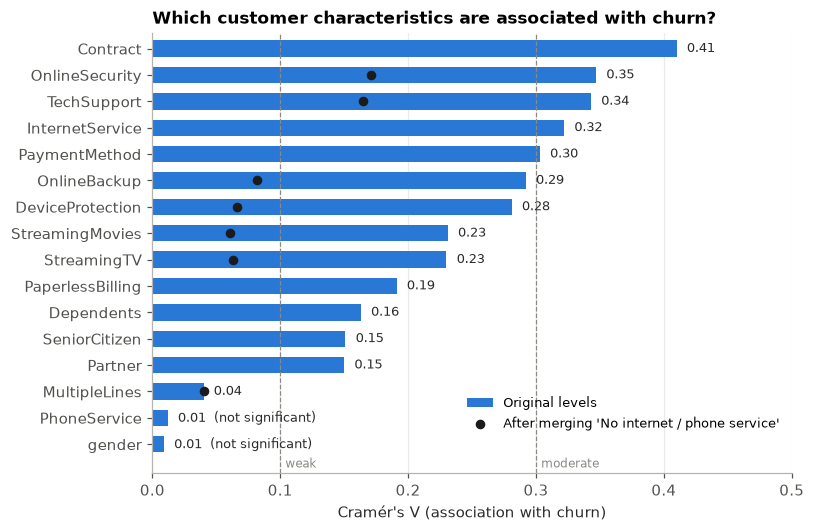

In [3]:
# Cell 3 - Figure 01: strength of association with churn (Cramér's V)
d = cat_drivers.sort_values("cramers_v")
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(d["feature"], d["cramers_v"], color=BAR, height=0.62, label="Original levels")
merged = d.dropna(subset=["cramers_v_merged"])
ax.scatter(merged["cramers_v_merged"], merged["feature"], color="#1b1b1b", s=28, zorder=3,
           label="After merging 'No internet / phone service'")
for y, (v, vm, sig) in enumerate(zip(d["cramers_v"], d["cramers_v_merged"].fillna(0), d["significant"])):
    ax.text(max(v, vm) + 0.008, y, f"{v:.2f}" + ("" if sig else "  (not significant)"),
            va="center", fontsize=8.5, color="#2b2b2b")
for x, txt in [(0.1, "weak"), (0.3, "moderate")]:
    ax.axvline(x, color=GREY, lw=0.8, ls="--")
    ax.text(x + 0.004, -0.75, txt, color=GREY, fontsize=8, ha="left", va="center")
ax.set_xlabel("Cramér's V (association with churn)")
ax.set_xlim(0, 0.5)
ax.set_ylim(-1.1, len(d) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_title("Which customer characteristics are associated with churn?", loc="left")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", bbox_to_anchor=(1, 0.07), fontsize=8.5)
save(fig, "01_cramers_v")
plt.show()

Saved figure: 02_churn_by_contract_internet_payment


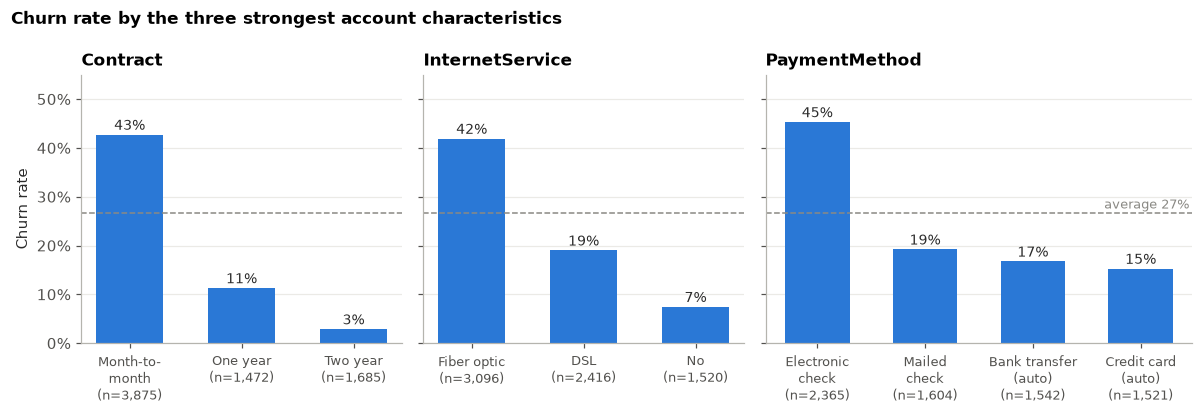

In [4]:
# Cell 4 - Figure 02: churn rate by contract, internet service and payment method
panels = ["Contract", "InternetService", "PaymentMethod"]
short = {"Bank transfer (automatic)": "Bank transfer\n(auto)", "Credit card (automatic)": "Credit card\n(auto)",
         "Electronic check": "Electronic\ncheck", "Mailed check": "Mailed\ncheck", "Month-to-month": "Month-to-\nmonth"}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True,
                         gridspec_kw={"width_ratios": [3, 3, 4]})
for ax, col in zip(axes, panels):
    g = eda.groupby(col)[C.TARGET].agg(rate="mean", n="size").sort_values("rate", ascending=False)
    labels = [f"{short.get(i, i)}\n(n={n:,})" for i, n in zip(g.index, g["n"])]
    ax.bar(labels, g["rate"], color=BAR, width=0.6)
    for x, r in enumerate(g["rate"]):
        ax.text(x, r + 0.01, f"{r:.0%}", ha="center", fontsize=9, color="#2b2b2b")
    ax.axhline(OVERALL, color=GREY, ls="--", lw=1)
    ax.set_title(col, loc="left")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8.5)
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set_ylim(0, 0.55)
axes[-1].text(3.45, OVERALL + 0.01, f"average {OVERALL:.0%}", color=GREY, fontsize=8.5, ha="right")
fig.suptitle("Churn rate by the three strongest account characteristics", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout()
save(fig, "02_churn_by_contract_internet_payment")
plt.show()

In [5]:
# Cell 5 - Numeric features: Mann–Whitney U test and rank-biserial effect size
rows = []
churned = eda[eda[C.TARGET] == 1]
stayed = eda[eda[C.TARGET] == 0]
for col in NUMERIC:
    u, p = mannwhitneyu(churned[col], stayed[col], alternative="two-sided")
    r = 2 * u / (len(churned) * len(stayed)) - 1          # > 0: churners tend to have higher values
    rows.append({
        "feature": col,
        "median_stayed": stayed[col].median(),
        "median_churned": churned[col].median(),
        "mean_stayed": round(stayed[col].mean(), 2),
        "mean_churned": round(churned[col].mean(), 2),
        "p_value": p,
        "significant": SIGNIFICANT[col],          # Holm-corrected (Cell 2)
        "rank_biserial_r": round(r, 3),
    })

num_drivers = pd.DataFrame(rows)
num_drivers.to_csv(C.TABLES_DIR / "05_churn_drivers_numeric.csv", index=False)
num_drivers.style.format({"p_value": "{:.1e}", "median_stayed": "{:g}", "median_churned": "{:g}"})

,feature,median_stayed,median_churned,mean_stayed,mean_churned,p_value,significant,rank_biserial_r
0,tenure,38,10,37.650000,17.980000,6.0e-211,True,-0.483000
1,MonthlyCharges,64.45,79.65,61.310000,74.440000,8.5e-54,True,0.241000
2,TotalCharges,1683.6,703.55,2555.340000,1531.800000,2.0e-84,True,-0.303000
3,n_services,4,4,4.170000,4.070000,6.7e-01,False,-0.007000


Saved figure: 03_tenure_and_charges_by_churn


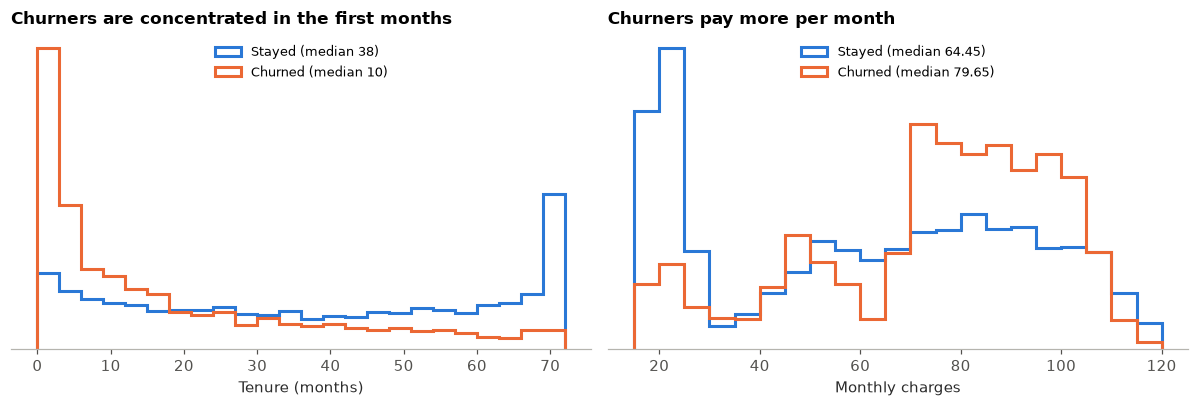

In [6]:
# Cell 6 - Figure 03: how tenure and monthly charges differ between churners and stayers
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
specs = [("tenure", np.arange(0, 75, 3), "Tenure (months)"),
         ("MonthlyCharges", np.arange(15, 125, 5), "Monthly charges")]
for ax, (col, bins, label) in zip(axes, specs):
    for data, colour, name in [(stayed, STAYED, "Stayed"), (churned, CHURNED, "Churned")]:
        ax.hist(data[col], bins=bins, density=True, histtype="step", lw=2, color=colour,
                label=f"{name} (median {data[col].median():g})")
    ax.set_xlabel(label)
    ax.set_yticks([])
    ax.grid(visible=False)
    ax.spines["left"].set_visible(False)
    ax.legend(fontsize=8.5, loc="upper center")
axes[0].set_title("Churners are concentrated in the first months", loc="left")
axes[1].set_title("Churners pay more per month", loc="left")
fig.tight_layout()
save(fig, "03_tenure_and_charges_by_churn")
plt.show()

### Q2 findings
1. **Contract is the strongest driver (V = 0.41):** month-to-month 43% churn, one-year 11%, two-year 3%.
2. **Next (V ≈ 0.30–0.35):** fibre optic 42% (DSL 19%, no internet 7%); electronic check 45% (other methods 15–19%); no online security / tech support 42%.
3. **Add-on effect is partly an internet effect:** after merging "No internet service", V for OnlineSecurity and TechSupport halves to about 0.17.
4. **Demographics matter less (V ≈ 0.15–0.16).** Gender and PhoneService: no association. MultipleLines: significant but negligible (V = 0.04).
5. **Churners are newer and pay more:** median tenure 10 vs 38 months (r = −0.48); median monthly charge 79.65 vs 64.45 (r = 0.24).
6. **n_services:** no overall difference, because churn follows an inverted U.

Churn risk ranges from 3% to 45% between groups, so one 0.5 threshold for everyone is unlikely to suit all groups.

**Outputs:** Tables 04–05; Figures 01–03.

## Q3. When do customers churn?
Churn rate by tenure band, overall and by contract type. Note: the data is a snapshot, so the rate is the share of customers at that tenure who left last month.

In [7]:
# Cell 7 - Churn rate by tenure band, overall and by contract
BANDS = [0, 6, 12, 24, 36, 48, 60, 72]
BAND_LABELS = ["1–6", "7–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
eda["tenure_band"] = pd.cut(eda["tenure"], BANDS, labels=BAND_LABELS)

by_band = eda.groupby("tenure_band", observed=True)[C.TARGET].agg(
    customers="size", churners="sum", churn_rate="mean")
by_band["share_of_all_churners"] = by_band["churners"] / eda[C.TARGET].sum()

rate_by_contract = eda.pivot_table(index="tenure_band", columns="Contract", values=C.TARGET,
                                   aggfunc="mean", observed=True)
n_by_contract = eda.pivot_table(index="tenure_band", columns="Contract", values=C.TARGET,
                                aggfunc="size", observed=True)

tenure_table = by_band.join(rate_by_contract.add_prefix("churn rate: ")).join(n_by_contract.add_prefix("n: "))
tenure_table.to_csv(C.TABLES_DIR / "06_churn_by_tenure_contract.csv")

first_year = (eda.loc[eda[C.TARGET] == 1, "tenure"] <= 12).mean()
print(f"Churners in their first 12 months: {first_year:.1%} of all churners")
print(f"Customers in their first 12 months: {(eda['tenure'] <= 12).mean():.1%} of all customers")
tenure_table.style.format({c: "{:.1%}" for c in tenure_table.columns if "rate" in c or "share" in c})

Churners in their first 12 months: 55.5% of all churners
Customers in their first 12 months: 30.9% of all customers


,customers,churners,churn_rate,share_of_all_churners,churn rate: Month-to-month,churn rate: One year,churn rate: Two year,n: Month-to-month,n: One year,n: Two year
tenure_band,,,,,,,,,,
1–6,1470,784,53.3%,41.9%,55.2%,10.5%,0.0%,1413,38,19
7–12,705,253,35.9%,13.5%,42.0%,10.6%,0.0%,581,85,39
13–24,1024,294,28.7%,15.7%,37.7%,8.1%,0.0%,737,197,90
25–36,832,180,21.6%,9.6%,32.5%,8.0%,2.1%,486,250,96
37–48,762,145,19.0%,7.8%,33.5%,13.1%,2.2%,316,268,178
49–60,832,120,14.4%,6.4%,27.8%,13.7%,4.0%,234,321,277
61–72,1407,93,6.6%,5.0%,22.2%,12.1%,3.1%,108,313,986


Saved figure: 04_churn_by_tenure_contract


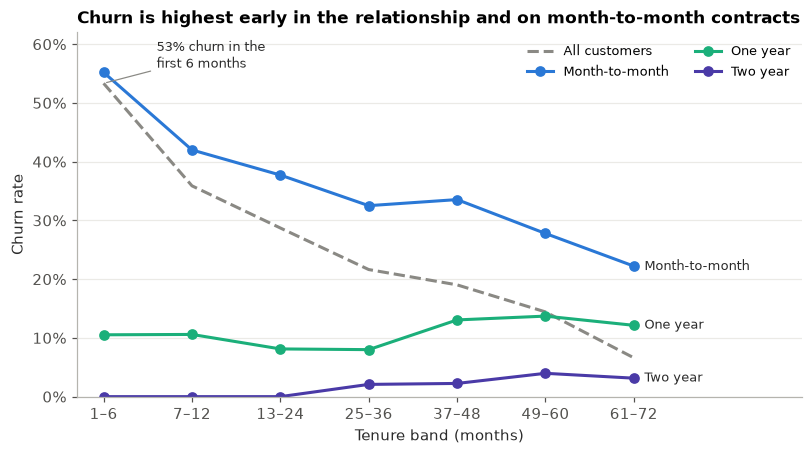

In [8]:
# Cell 8 - Figure 04: churn rate over the customer lifecycle, by contract
CONTRACT_COLOURS = {"Month-to-month": "#2a78d6", "One year": "#1baf7a", "Two year": "#4a3aa7"}
x = np.arange(len(BAND_LABELS))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(x, by_band["churn_rate"], color=GREY, lw=2, ls="--", label="All customers")
for contract, colour in CONTRACT_COLOURS.items():
    rates = rate_by_contract[contract]
    ax.plot(x, rates, color=colour, lw=2, marker="o", ms=6, label=contract)
    ax.text(x[-1] + 0.12, rates.iloc[-1], contract, color="#2b2b2b", fontsize=8.5, va="center")
ax.annotate(f"{by_band['churn_rate'].iloc[0]:.0%} churn in the\nfirst 6 months",
            xy=(0, by_band["churn_rate"].iloc[0]), xytext=(0.6, 0.56), fontsize=8.5, color="#2b2b2b",
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_xticks(x, BAND_LABELS)
ax.set_xlim(-0.3, len(x) + 0.9)
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.62)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=8.5, ncol=2)
ax.set_title("Churn is highest early in the relationship and on month-to-month contracts", loc="left")
save(fig, "04_churn_by_tenure_contract")
plt.show()

### Q3 findings
1. **Churn is concentrated early:** 53% churn in the first 6 months, 7% after 5 years. First-year customers are 31% of the base but 55% of churners.
2. **Contract changes the whole curve:** month-to-month starts at 55% and is still 22–28% after 4 years; one-year 8–14%; two-year 0–4%.
3. **Tenure and contract overlap:** almost all new customers are month-to-month, so a model needs both.

Risk depends on the lifecycle stage, which supports using tenure in the segmentation (Stage 2).

## Q4. Is every lost customer equally costly?
Uses MonthlyCharges as each customer's value (revenue lost per month) and a 12-month horizon (`config.VALUE_HORIZON_MONTHS`).

In [9]:
# Cell 9 - Revenue lost to churn (headline KPIs)
monthly = eda["MonthlyCharges"]
churn = eda[C.TARGET] == 1
lost = monthly[churn]
top20_share = np.sort(lost.values)[::-1][: int(0.2 * len(lost))].sum() / lost.sum()

kpis = pd.DataFrame([
    ("Customers",                                        f"{len(eda):,}"),
    ("Churners",                                         f"{churn.sum():,}  ({churn.mean():.1%} of customers)"),
    ("Monthly revenue, all customers",                   f"{monthly.sum():,.0f}"),
    ("Monthly revenue lost to churn",                    f"{lost.sum():,.0f}  ({lost.sum() / monthly.sum():.1%} of revenue)"),
    ("Average monthly charge: churned vs stayed",        f"{lost.mean():.2f} vs {monthly[~churn].mean():.2f}"),
    (f"Revenue at risk over {C.VALUE_HORIZON_MONTHS} months (assumption)", f"{lost.sum() * C.VALUE_HORIZON_MONTHS:,.0f}"),
    ("Share of lost revenue from the top 20% of churners", f"{top20_share:.1%}"),
], columns=["KPI", "Value"]).set_index("KPI")
kpis

,Value
KPI,
Customers,"7,032"
Churners,"1,869 (26.6% of customers)"
"Monthly revenue, all customers","455,661"
Monthly revenue lost to churn,"139,131 (30.5% of revenue)"
Average monthly charge: churned vs stayed,74.44 vs 61.31
Revenue at risk over 12 months (assumption),"1,669,570"
Share of lost revenue from the top 20% of churners,27.6%


In [10]:
# Cell 10 - Value groups: new vs long-standing, high- vs low-paying (split at the medians)
med_tenure, med_charge = eda["tenure"].median(), eda["MonthlyCharges"].median()
new_or_long = pd.Series(np.where(eda["tenure"] <= med_tenure, "New", "Long-standing"), index=eda.index)
high_or_low = np.where(eda["MonthlyCharges"] > med_charge, "high-paying", "low-paying")
eda["value_group"] = new_or_long + ", " + high_or_low

value_groups = eda.groupby("value_group").agg(
    customers=(C.TARGET, "size"),
    churn_rate=(C.TARGET, "mean"),
    avg_monthly_charge=("MonthlyCharges", "mean"),
)
value_groups["pct_of_customers"] = value_groups["customers"] / len(eda)
value_groups["pct_of_churners"] = eda[churn].groupby("value_group").size() / churn.sum()
value_groups["pct_of_lost_revenue"] = eda[churn].groupby("value_group")["MonthlyCharges"].sum() / lost.sum()
value_groups = value_groups.sort_values("pct_of_lost_revenue", ascending=False)
value_groups.to_csv(C.TABLES_DIR / "07_value_groups.csv")

print(f"Split at median tenure = {med_tenure:g} months and median monthly charge = {med_charge:.2f}")
value_groups.style.format({"churn_rate": "{:.1%}", "avg_monthly_charge": "{:.2f}", "pct_of_customers": "{:.1%}",
                           "pct_of_churners": "{:.1%}", "pct_of_lost_revenue": "{:.1%}"})

Split at median tenure = 29 months and median monthly charge = 70.35


,customers,churn_rate,avg_monthly_charge,pct_of_customers,pct_of_churners,pct_of_lost_revenue
value_group,,,,,,
"New, high-paying",1473,58.1%,85.56,20.9%,45.8%,53.0%
"Long-standing, high-paying",2040,18.7%,94.29,29.0%,20.4%,26.3%
"New, low-paying",2085,26.5%,39.07,29.7%,29.6%,17.8%
"Long-standing, low-paying",1434,5.5%,38.92,20.4%,4.2%,2.8%


Saved figure: 05_customers_vs_lost_revenue


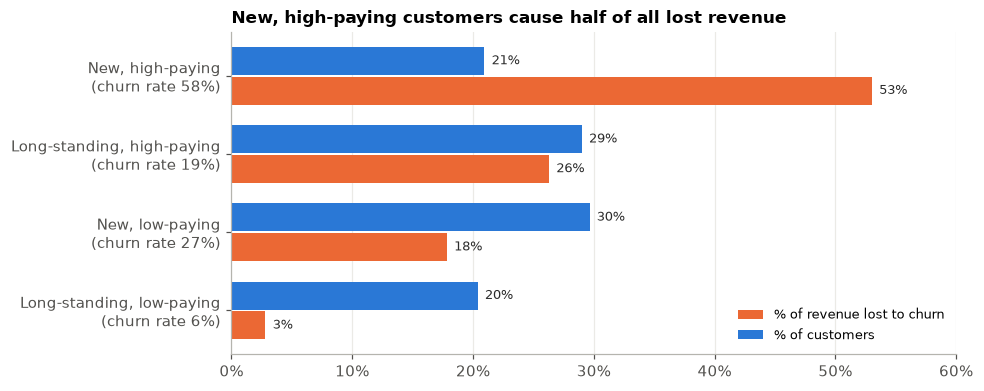

In [11]:
# Cell 11 - Figure 05: share of customers vs share of lost revenue, by value group
d = value_groups.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(y + 0.19, d["pct_of_customers"], height=0.36, color=STAYED, label="% of customers")
ax.barh(y - 0.19, d["pct_of_lost_revenue"], height=0.36, color=CHURNED, label="% of revenue lost to churn")
for yi, (pc, pl) in enumerate(zip(d["pct_of_customers"], d["pct_of_lost_revenue"])):
    ax.text(pc + 0.006, yi + 0.19, f"{pc:.0%}", va="center", fontsize=8.5, color="#2b2b2b")
    ax.text(pl + 0.006, yi - 0.19, f"{pl:.0%}", va="center", fontsize=8.5, color="#2b2b2b")
ax.set_yticks(y, [f"{g}\n(churn rate {r:.0%})" for g, r in zip(d.index, d["churn_rate"])])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlim(0, 0.6)
ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", fontsize=8.5)
ax.set_title("New, high-paying customers cause half of all lost revenue", loc="left")
save(fig, "05_customers_vs_lost_revenue")
plt.show()

Saved figure: 06_tenure_vs_charges_scatter


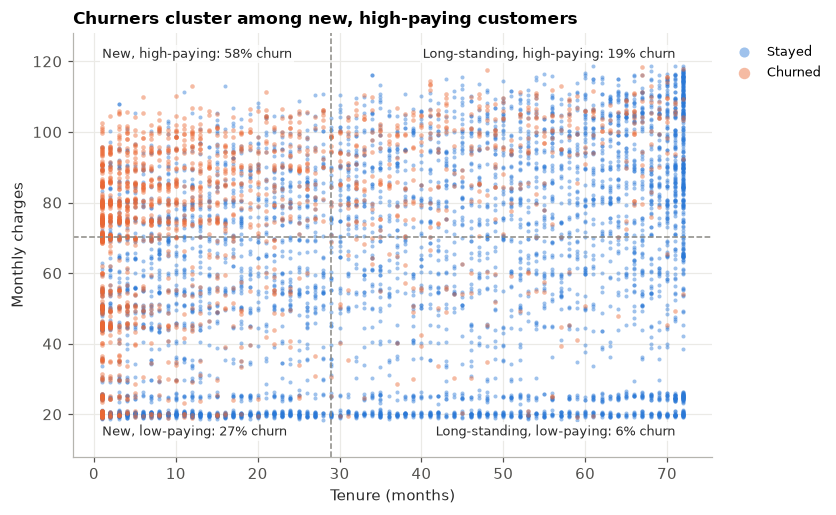

In [12]:
# Cell 12 - Figure 06: where churners sit on tenure and monthly charges
fig, ax = plt.subplots(figsize=(7.5, 5))
for data, colour, name, size in [(eda[~churn], STAYED, "Stayed", 7), (eda[churn], CHURNED, "Churned", 9)]:
    ax.scatter(data["tenure"], data["MonthlyCharges"], s=size, color=colour, alpha=0.45, lw=0, label=name)
ax.axvline(med_tenure, color=GREY, ls="--", lw=1)
ax.axhline(med_charge, color=GREY, ls="--", lw=1)
for (tx, ty, ha), group in zip([(1, 121, "left"), (71, 121, "right"), (1, 14, "left"), (71, 14, "right")],
                               ["New, high-paying", "Long-standing, high-paying", "New, low-paying", "Long-standing, low-paying"]):
    ax.text(tx, ty, f"{group}: {value_groups.loc[group, 'churn_rate']:.0%} churn", ha=ha, fontsize=8.5,
            color="#2b2b2b", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charges")
ax.set_ylim(8, 128)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5, markerscale=2.5)
ax.set_title("Churners cluster among new, high-paying customers", loc="left")
save(fig, "06_tenure_vs_charges_scatter")
plt.show()

### Q4 findings
1. **Churners are 26.6% of customers but 30.5% of monthly revenue** (about 139,000 a month, about 1.67 million over 12 months). They pay 74.44 a month on average vs 61.31 for stayers.
2. **New, high-paying customers:** 21% of the base, 58% churn, **53% of lost revenue**.
3. **Long-standing, high-paying customers:** only 19% churn but 26% of lost revenue – counting churners alone under-weights them.
4. Value is only moderately skewed (top 20% of churners = 28% of lost revenue).

The median cut-offs are for illustration only; Stage 2 replaces them with K-Means segments.

## Stage 1 summary

| Finding | Evidence | Consequence for the method |
|---|---|---|
| Data is clean and consistent | No duplicates, outliers or contradictions | Preparation fixed in `src/features.py` |
| Contract, tenure, internet type and payment method drive churn | V 0.30–0.41; tenure r = −0.48 | The contribution is the decision, not the drivers |
| Risk is concentrated early and on month-to-month contracts | 53% churn in months 1–6 | Tenure belongs in the segmentation |
| Churn risk varies from 3% to 58% across groups | Q2–Q4 | Motivates segment-level thresholds |
| Lost revenue is concentrated in high-paying customers | 26.6% of customers, 30.5% of revenue | Supports value-based segmentation and cost-sensitive evaluation |

**Input to Stage 2:** tenure and MonthlyCharges.